# UCS420 Cognitive Computing - Assignment 9

## Vision based Cognitive System

Name: Vishu Verma

Roll number: 1024170242

Both assistants follow the same idea: **perceive** (computer vision model on the image) -> **understand** (match the raw output against stored knowledge) -> **respond** (give the user something useful in plain language).

In [1]:
import os, re, glob, difflib, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

## Question 1 - Cognitive assistant for reading medicine bottle labels

**Dataset:** 10 photos of real medicine bottles downloaded from Wikimedia Commons (category "Pill bottles" and "Medicine bottles"), saved in `medicine_labels/`. They have curved labels, glare, small text and different backgrounds, so they are a good test.

**Pipeline**
1. Load the image and preprocess it with OpenCV.
2. Read the text with EasyOCR (CRAFT text detector + CRNN recogniser).
3. Clean the OCR text and find the medicine name using fuzzy matching (plus prefix matching for cut off words) against a small drug knowledge base, because OCR often gets a few letters wrong.
4. Extract strength (mg / ml), number of tablets and NDC code with regex.
5. Generate a short spoken style summary with the use and the main warning for the medicine.

10 images


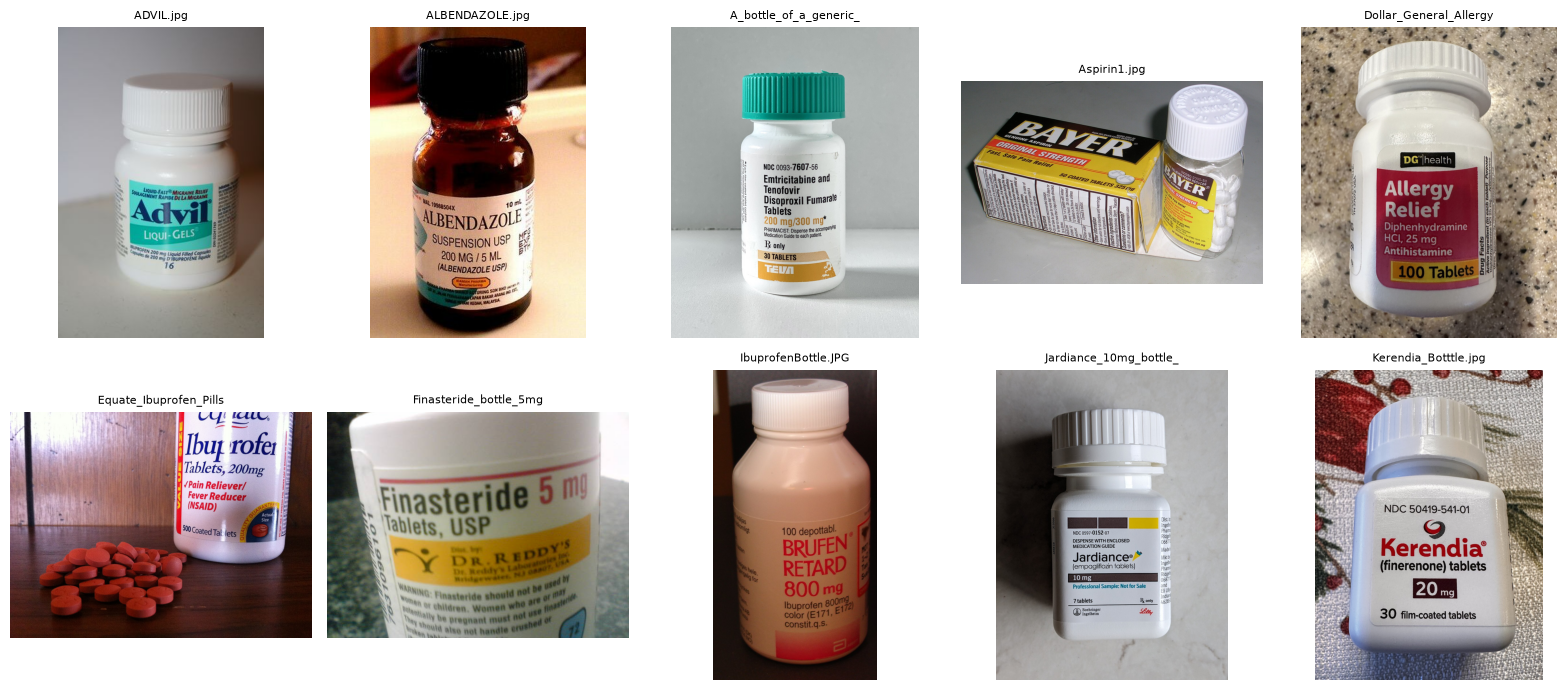

In [2]:
files = sorted(glob.glob("medicine_labels/*"))
print(len(files), "images")

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, f in zip(axes.ravel(), files):
    ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB))
    ax.set_title(os.path.basename(f)[:22], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Step 1 - Preprocessing

Resize so the longer side is around 1280 px and improve local contrast with CLAHE on the L channel, which helps with glare on shiny bottles.

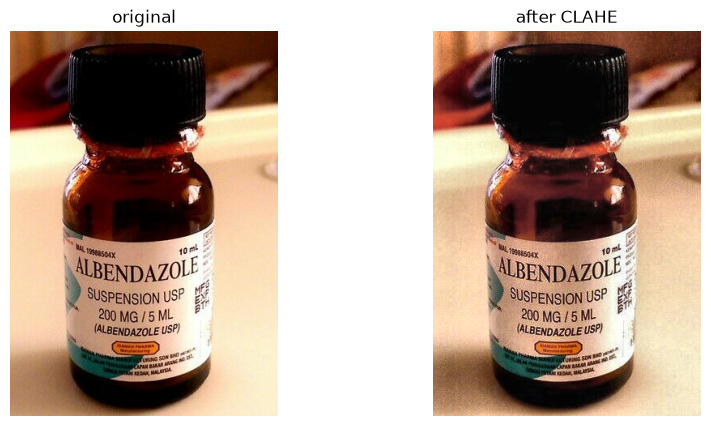

In [3]:
def preprocess(path, max_side=1280):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)

sample = files[1]
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(cv2.cvtColor(cv2.imread(sample), cv2.COLOR_BGR2RGB)); ax[0].set_title("original")
ax[1].imshow(cv2.cvtColor(preprocess(sample), cv2.COLOR_BGR2RGB)); ax[1].set_title("after CLAHE")
for a in ax: a.axis("off")
plt.show()

### Step 2 - OCR with EasyOCR

In [4]:
import easyocr

reader = easyocr.Reader(["en"], gpu=False, verbose=False)

def read_label(path):
    img = preprocess(path)
    result = reader.readtext(img)          # list of (box, text, confidence)
    return img, result

img, result = read_label(sample)
for box, text, conf in result:
    print(f"{conf:.2f}  {text}")

1.00  ALBENDAZOLE
0.92  SUSPENSION USP
0.83  200 MG /5 ML
0.82  (ALBENDAZOLE USP)
0.20  t0mt


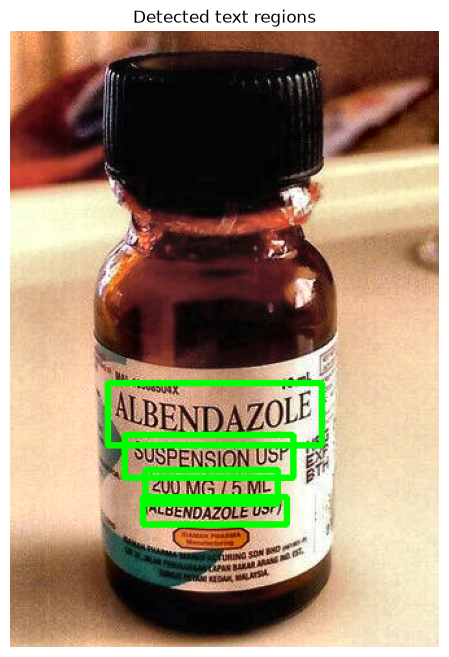

In [5]:
def draw_boxes(img, result, min_conf=0.3):
    out = img.copy()
    for box, text, conf in result:
        if conf < min_conf:
            continue
        pts = np.array(box, dtype=np.int32)
        cv2.polylines(out, [pts], True, (0, 255, 0), 3)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(draw_boxes(img, result))
plt.axis("off")
plt.title("Detected text regions")
plt.show()

### Step 3 - Knowledge base and fuzzy matching

The OCR output is noisy ("aSpinin", "Jardiancee", "rofel"), so exact search would miss many medicines. I keep a small knowledge base with brand names and generic names and use `difflib.SequenceMatcher` to match every OCR word to the closest name. A match is accepted if the similarity is at least 0.8.

Some labels are only partly visible because the bottle is curved ("Adv" for Advil, "Ibu" for Ibuprofen), so if a word of 3+ letters is the start of a stored name I give it a score of 0.85.

In [6]:
DRUGS = {
    "ibuprofen": {"names": ["ibuprofen", "advil", "brufen", "motrin"],
                  "use": "pain reliever and fever reducer (NSAID)",
                  "warning": "take with food, can cause stomach bleeding, avoid if you have ulcers or kidney problems"},
    "aspirin": {"names": ["aspirin", "bayer"],
                "use": "pain reliever, fever reducer and blood thinner",
                "warning": "do not give to children or teenagers (Reye's syndrome), can cause stomach bleeding"},
    "diphenhydramine": {"names": ["diphenhydramine", "benadryl"],
                        "use": "antihistamine for allergy, sneezing and runny nose",
                        "warning": "causes drowsiness, do not drive or drink alcohol after taking it"},
    "finasteride": {"names": ["finasteride", "proscar", "propecia"],
                    "use": "treats enlarged prostate and hair loss in men",
                    "warning": "women who are or may be pregnant must not handle broken tablets"},
    "empagliflozin": {"names": ["empagliflozin", "jardiance"],
                      "use": "lowers blood sugar in type 2 diabetes",
                      "warning": "drink enough water, watch for dehydration and urinary infections"},
    "finerenone": {"names": ["finerenone", "kerendia"],
                   "use": "protects the kidneys and heart in chronic kidney disease with type 2 diabetes",
                   "warning": "can raise potassium levels, blood tests are needed regularly"},
    "albendazole": {"names": ["albendazole", "zentel"],
                    "use": "treats worm infections",
                    "warning": "not to be used in pregnancy, shake the suspension well before use"},
    "emtricitabine/tenofovir": {"names": ["emtricitabine", "tenofovir", "truvada"],
                                "use": "HIV treatment and prevention (PrEP)",
                                "warning": "do not stop suddenly, kidney function should be checked"},
    "paracetamol": {"names": ["paracetamol", "acetaminophen", "tylenol", "crocin"],
                    "use": "pain reliever and fever reducer",
                    "warning": "do not take more than the daily limit, overdose damages the liver"},
}

NAME_TO_DRUG = {n: d for d, info in DRUGS.items() for n in info["names"]}

def similarity(a, b):
    s = difflib.SequenceMatcher(None, a, b).ratio()
    if len(a) >= 3 and b.startswith(a):
        s = max(s, 0.85)
    return s

def find_drug(words, threshold=0.8):
    best = (None, None, 0.0)      # (drug, ocr word, score)
    for w in words:
        w = w.lower()
        if len(w) < 3:
            continue
        for name, drug in NAME_TO_DRUG.items():
            s = similarity(w, name)
            if s > best[2]:
                best = (drug, w, s)
    return best if best[2] >= threshold else (None, None, best[2])

print(find_drug(["aSpinin"]))
print(find_drug(["Jardiancee"]))
print(find_drug(["Ibu", "Tablets"]))
print(find_drug(["hello", "world"]))

('aspirin', 'aspinin', 0.8571428571428571)
('empagliflozin', 'jardiancee', 0.9473684210526315)
('ibuprofen', 'ibu', 0.85)
(None, None, 0.4444444444444444)


### Step 4 - Extracting strength, count and NDC with regex

In [7]:
def extract_details(text):
    t = text.replace(",", " ")
    strength = re.findall(r"(\d+(?:\.\d+)?)\s*(mg|mcg|ml|g)\b", t, flags=re.I)
    count = re.search(r"([2-9]|\d{2,3})\s*(?:film-coated\s+)?(tablets|caplets|capsules|liqui-gels|softgels)", t, flags=re.I)
    ndc = re.search(r"NDC\s*([\d-]{9,13})", t, flags=re.I)
    return {
        "strength": ", ".join(f"{n} {u.lower()}" for n, u in dict.fromkeys(strength)) or None,
        "count": f"{count.group(1)} {count.group(2).lower()}" if count else None,
        "ndc": ndc.group(1) if ndc else None,
    }

print(extract_details("Kerendia (finerenone) tablets 20mg 30 film-coated tablets NDC 50419-541-01"))

{'strength': '20 mg', 'count': '30 tablets', 'ndc': '50419-541-01'}


### Step 5 - The assistant

In [8]:
def assistant(path, min_conf=0.2):
    img, result = read_label(path)
    words = [t for _, t, c in result if c >= min_conf]
    text = " ".join(words)
    tokens = re.findall(r"[A-Za-z]+", text)

    drug, matched, score = find_drug(tokens)
    info = extract_details(text)

    if drug is None:
        reply = "Sorry, I could not recognise this medicine. Please hold the label closer to the camera."
    else:
        d = DRUGS[drug]
        reply = f"This looks like {drug.title()}"
        if info["strength"]:
            reply += f", {info['strength']}"
        if info["count"]:
            reply += f", {info['count']} in the bottle"
        reply += f". Use: {d['use']}. Warning: {d['warning']}."
    return {"file": os.path.basename(path), "ocr_text": text, "matched_word": matched,
            "score": round(score, 2), "drug": drug, **info, "reply": reply, "img": img, "result": result}

outputs = [assistant(f) for f in files]

In [9]:
for o in outputs:
    print("=" * 90)
    print("Image   :", o["file"])
    print("OCR     :", o["ocr_text"][:160])
    print("Matched :", o["matched_word"], "->", o["drug"], f"(score {o['score']})")
    print("Details : strength =", o["strength"], "| count =", o["count"], "| NDC =", o["ndc"])
    print("Reply   :", o["reply"])

Image   : ADVIL.jpg
OCR     : Adv Liqui-GELS"
Matched : adv -> ibuprofen (score 0.85)
Details : strength = None | count = None | NDC = None
Reply   : This looks like Ibuprofen. Use: pain reliever and fever reducer (NSAID). Warning: take with food, can cause stomach bleeding, avoid if you have ulcers or kidney problems.
Image   : ALBENDAZOLE.jpg
OCR     : ALBENDAZOLE SUSPENSION USP 200 MG /5 ML (ALBENDAZOLE USP) t0mt
Matched : albendazole -> albendazole (score 1.0)
Details : strength = 200 mg, 5 ml | count = None | NDC = None
Reply   : This looks like Albendazole, 200 mg, 5 ml. Use: treats worm infections. Warning: not to be used in pregnancy, shake the suspension well before use.
Image   : A_bottle_of_a_generic_version_of_Truvada.jpg
OCR     : NDC 0093-7607-56 Emtricitabine Tenofovir Disoproxil Tablets 200 mg/300 mg PHARMACIST: Dispense the Guide to each R only 30 TABLETS Tevn and Fumarate accompanyin
Matched : emtricitabine -> emtricitabine/tenofovir (score 1.0)
Details : strength = 2

### Results

In [10]:
truth = {
    "ADVIL.jpg": "ibuprofen",
    "ALBENDAZOLE.jpg": "albendazole",
    "A_bottle_of_a_generic_version_of_Truvada.jpg": "emtricitabine/tenofovir",
    "Aspirin1.jpg": "aspirin",
    "Dollar_General_Allergy_Relief_Diphenhydramine_Bottle.jpg": "diphenhydramine",
    "Equate_Ibuprofen_Pills_and_Bottle.JPG": "ibuprofen",
    "Finasteride_bottle_5mg.jpg": "finasteride",
    "IbuprofenBottle.JPG": "ibuprofen",
    "Jardiance_10mg_bottle__front_view.jpg": "empagliflozin",
    "Kerendia_Botttle.jpg": "finerenone",
}
res = pd.DataFrame([{k: o[k] for k in ["file", "matched_word", "score", "drug", "strength", "count"]} for o in outputs])
res["expected"] = res.file.map(truth)
res["correct"] = res.drug == res.expected
pd.set_option("display.max_colwidth", 40)
print(res.to_string(index=False))
print(f"\nMedicine identified correctly: {res.correct.sum()} / {len(res)}")

                                                    file    matched_word  score                    drug       strength       count                expected  correct
                                               ADVIL.jpg             adv   0.85               ibuprofen            NaN         NaN               ibuprofen     True
                                         ALBENDAZOLE.jpg     albendazole   1.00             albendazole   200 mg, 5 ml         NaN             albendazole     True
            A_bottle_of_a_generic_version_of_Truvada.jpg   emtricitabine   1.00 emtricitabine/tenofovir 200 mg, 300 mg  30 tablets emtricitabine/tenofovir     True
                                            Aspirin1.jpg           bayer   1.00                 aspirin         325 mg 910 tablets                 aspirin     True
Dollar_General_Allergy_Relief_Diphenhydramine_Bottle.jpg diphenhydramine   1.00         diphenhydramine          25 mg         NaN         diphenhydramine     True
                

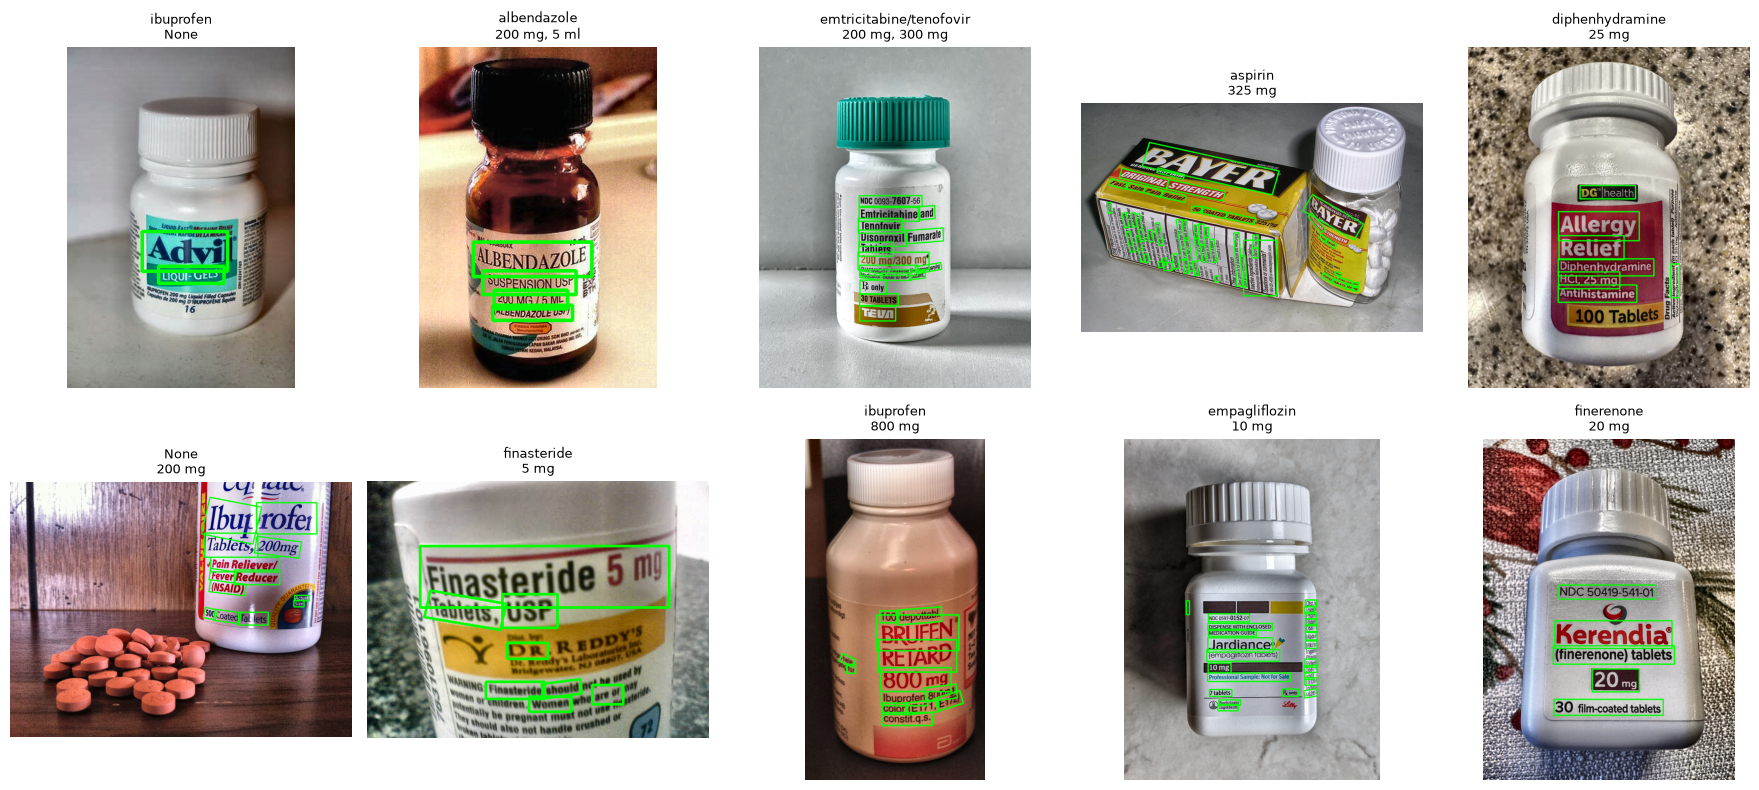

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, o in zip(axes.ravel(), outputs):
    ax.imshow(draw_boxes(o["img"], o["result"]))
    ax.set_title(f"{o['drug']}\n{o['strength']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observations**
- EasyOCR reads the big printed name well even on curved bottles, but small text (directions, warnings) comes out broken because of the curve and glare.
- Raw OCR words are often slightly wrong ("aspikin", "Jardiancee") or cut off by the curve ("Adv", "Ibu"). Fuzzy matching plus prefix matching against the knowledge base still finds the right medicine.
- Brand names (Bayer, Brufen, Kerendia) are mapped to the generic drug, so the reply is the same whatever brand the user has.
- Strength and tablet count are found by regex when OCR keeps the number and the unit together. OCR noise can still give a wrong value, e.g. "910 tablets" on the Aspirin bottle where random digits got joined to "TABLETS".
- The Equate ibuprofen photo fails because the name is printed vertically and only "rofel" is read, which is too far from any stored name.
- The knowledge base is what makes it a cognitive assistant and not just OCR: it turns text into an answer the user can act on (what the medicine is for and what to be careful about). In a real system the knowledge base could be replaced with a drug database like openFDA.

## Question 2 - Emotion-aware cognitive assistant using facial expression detection

**Model:** FER+ emotion recognition CNN from the ONNX Model Zoo (`emotion-ferplus-8.onnx`, trained by Microsoft on the FER+ relabelled FER-2013 images). It takes a 64x64 grayscale face and gives scores for 8 emotions. It is run with OpenCV's `dnn` module so no deep learning framework is needed.

**Face detection:** OpenCV Haar cascade (`haarcascade_frontalface_default.xml`).

**Test data:** 140 faces from the FER-2013 test set (20 per class except contempt, which FER-2013 doesn't have) in `faces/`. The file name has the true label.

**Assistant:** detects the emotion, keeps a short history of the user's mood and replies in a way that fits the mood.

In [12]:
import urllib.request

MODEL = "models/emotion-ferplus-8.onnx"
URL = "https://github.com/onnx/models/raw/main/validated/vision/body_analysis/emotion_ferplus/model/emotion-ferplus-8.onnx"
if not os.path.exists(MODEL):
    os.makedirs("models", exist_ok=True)
    urllib.request.urlretrieve(URL, MODEL)

net = cv2.dnn.readNetFromONNX(MODEL)
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

EMOTIONS = ["neutral", "happy", "surprise", "sad", "angry", "disgust", "fear", "contempt"]
print("model loaded, classes:", EMOTIONS)

model loaded, classes: ['neutral', 'happy', 'surprise', 'sad', 'angry', 'disgust', 'fear', 'contempt']


### Detection functions

In [13]:
def softmax(x):
    e = np.exp(x - x.max())
    return e / e.sum()

def predict_face(gray_face):
    x = cv2.resize(gray_face, (64, 64)).astype(np.float32).reshape(1, 1, 64, 64)
    net.setInput(x)
    return softmax(net.forward()[0])

def detect_emotions(img):
    """Returns a list of (box, emotion, confidence, probs) for every face in the image."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    if len(faces) == 0:
        # FER images are already cropped faces, so use the whole image
        faces = [(0, 0, gray.shape[1], gray.shape[0])]
    out = []
    for (x, y, w, h) in faces:
        p = predict_face(gray[y:y + h, x:x + w])
        k = int(np.argmax(p))
        out.append(((x, y, w, h), EMOTIONS[k], float(p[k]), p))
    return out

### Testing on the FER-2013 sample

In [14]:
face_files = sorted(glob.glob("faces/*.jpg"))
rows = []
for f in face_files:
    img = cv2.imread(f)
    _, emo, conf, p = detect_emotions(img)[0]
    rows.append({"file": os.path.basename(f), "true": os.path.basename(f).split("_")[0],
                 "predicted": emo, "confidence": round(conf, 2)})
pred = pd.DataFrame(rows)
print(pred.head(10).to_string(index=False))
print(f"\nAccuracy: {(pred.true == pred.predicted).mean():.2%}")

        file  true predicted  confidence
angry_01.jpg angry   neutral        0.63
angry_02.jpg angry   neutral        0.80
angry_03.jpg angry   neutral        0.74
angry_04.jpg angry  surprise        0.94
angry_05.jpg angry  surprise        0.42
angry_06.jpg angry     angry        0.70
angry_07.jpg angry       sad        0.53
angry_08.jpg angry     angry        0.68
angry_09.jpg angry   neutral        0.74
angry_10.jpg angry     angry        0.51

Accuracy: 47.86%


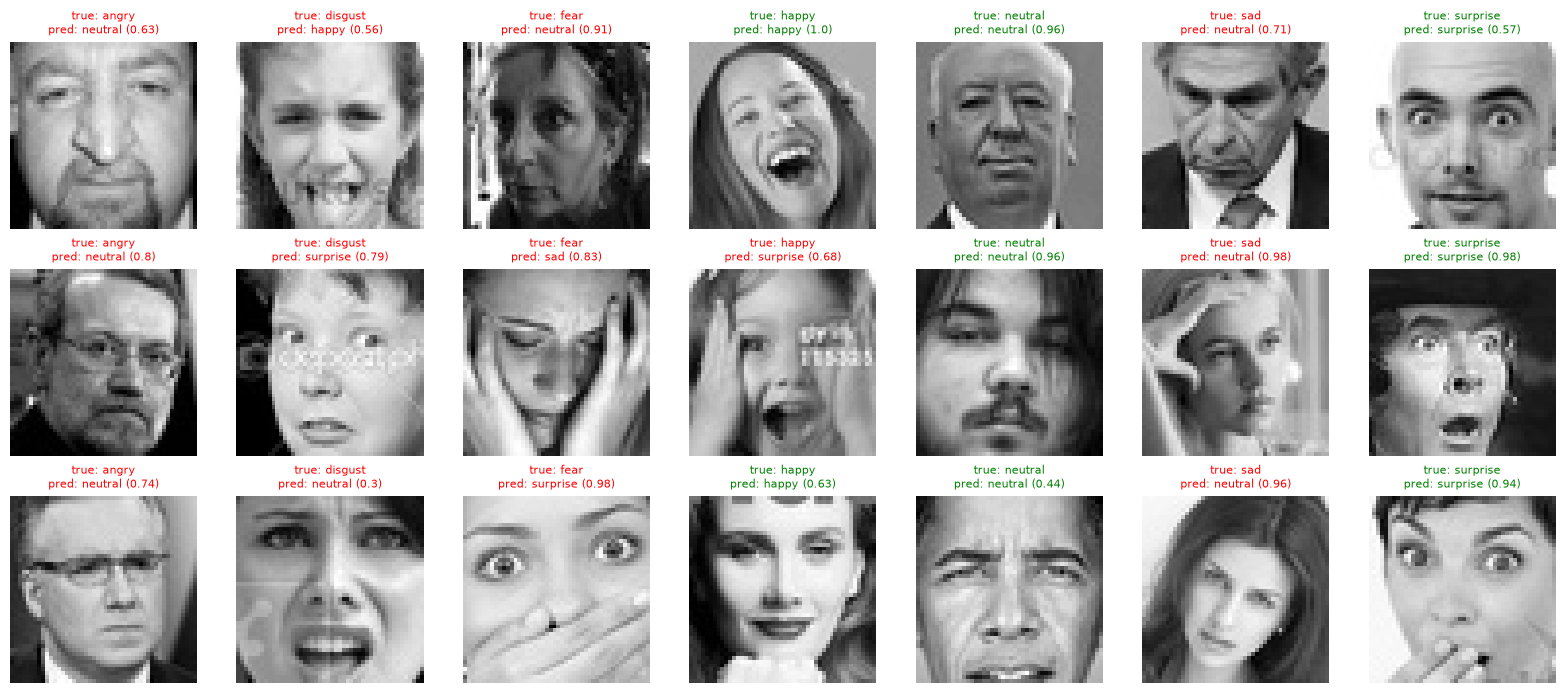

In [15]:
show = pred.groupby("true").head(3).index
fig, axes = plt.subplots(3, 7, figsize=(16, 7))
for ax, i in zip(axes.T.ravel(), show):
    f, r = face_files[i], pred.loc[i]
    ax.imshow(cv2.imread(f, 0), cmap="gray")
    color = "green" if r.true == r.predicted else "red"
    ax.set_title(f"true: {r.true}\npred: {r.predicted} ({r.confidence})", fontsize=8, color=color)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [16]:
print(pd.crosstab(pred.true, pred.predicted))
print()
print((pred.true == pred.predicted).groupby(pred.true).mean().round(2))

predicted  angry  contempt  disgust  happy  neutral  sad  surprise
true                                                              
angry          9         0        0      1        6    1         3
disgust        5         2        1      2        7    2         1
fear           2         0        0      3        6    7         2
happy          0         0        0     18        0    1         1
neutral        2         0        0      0       18    0         0
sad            0         0        0      1       14    5         0
surprise       0         0        0      1        2    1        16

true
angry       0.45
disgust     0.05
fear        0.00
happy       0.90
neutral     0.90
sad         0.25
surprise    0.80
dtype: float64


Happy, neutral and surprise are recognised well (80-90%). Most mistakes are sad and fear being predicted as neutral or sad, and disgust is almost never detected. FER-2013 images are only 48x48 and many of them are mild expressions, and FER+ labels were made by 10 people voting, so some original FER labels (especially disgust and fear) don't agree with FER+ anyway. Probability of the second best class is often close, so I use the full probability vector in the assistant instead of only the top label.

### The emotion-aware assistant

- Each new frame/photo is passed to the detector.
- The probabilities are averaged over the last few frames (a moving window), so one wrong frame doesn't change the reply.
- The mood is grouped into positive / neutral / negative and the assistant picks a reply and an action for that mood. If the user stays negative for several frames it escalates (suggests a break).

In [17]:
from collections import deque

RESPONSES = {
    "happy":    ("You look happy! Want me to save this as a good time to study the hard topics?", "keep going"),
    "surprise": ("You look surprised. Did something unexpected come up? I can explain it again.", "offer explanation"),
    "neutral":  ("All good. Let me know if you need anything.", "continue"),
    "sad":      ("You seem a bit low. Want me to play some music or take a short break?", "suggest break"),
    "angry":    ("You look frustrated. Let's slow down, I can break the problem into smaller steps.", "simplify task"),
    "disgust":  ("Something seems off. Do you want to skip this and come back later?", "offer skip"),
    "fear":     ("You look worried. Don't stress, we can go through it together step by step.", "reassure"),
    "contempt": ("Not convinced? I can show you another way to look at it.", "show alternative"),
}
NEGATIVE = {"sad", "angry", "disgust", "fear", "contempt"}

class EmotionAssistant:
    def __init__(self, window=3):
        self.history = deque(maxlen=window)
        self.negative_streak = 0

    def step(self, img):
        dets = detect_emotions(img)
        if not dets:
            return "I can't see your face.", None
        self.history.append(dets[0][3])
        avg = np.mean(self.history, axis=0)
        mood = EMOTIONS[int(np.argmax(avg))]

        self.negative_streak = self.negative_streak + 1 if mood in NEGATIVE else 0
        reply, action = RESPONSES[mood]
        if self.negative_streak >= 3:
            reply = "You have looked upset for a while now. Let's take a 5 minute break, I'll pause the session."
            action = "pause session"
        return reply, {"frame_emotion": dets[0][1], "smoothed_mood": mood,
                       "confidence": round(float(avg.max()), 2), "action": action}

**Simulated session**: a sequence of faces as if they were webcam frames of the same user, starting happy and then getting frustrated.

In [18]:
session = ["happy_01", "happy_03", "surprise_01", "neutral_01", "sad_04", "angry_06", "sad_05", "angry_08", "sad_06", "happy_04"]
bot = EmotionAssistant(window=3)

log = []
for name in session:
    reply, info = bot.step(cv2.imread(f"faces/{name}.jpg"))
    log.append({"frame": name, **info, "reply": reply})

pd.set_option("display.max_colwidth", 100)
pd.DataFrame(log)

,frame,frame_emotion,smoothed_mood,confidence,action,reply
0,happy_01,happy,happy,1.00,keep going,You look happy! Want me to save this as a good time to study the hard topics?
1,happy_03,happy,happy,0.82,keep going,You look happy! Want me to save this as a good time to study the hard topics?
2,surprise_01,surprise,happy,0.58,keep going,You look happy! Want me to save this as a good time to study the hard topics?
3,neutral_01,neutral,neutral,0.54,continue,All good. Let me know if you need anything.
4,sad_04,sad,neutral,0.43,continue,All good. Let me know if you need anything.
5,angry_06,angry,neutral,0.33,continue,All good. Let me know if you need anything.
6,sad_05,sad,sad,0.62,suggest break,You seem a bit low. Want me to play some music or take a short break?
7,angry_08,angry,angry,0.46,simplify task,"You look frustrated. Let's slow down, I can break the problem into smaller steps."
8,sad_06,sad,sad,0.47,pause session,"You have looked upset for a while now. Let's take a 5 minute break, I'll pause the session."
9,happy_04,happy,happy,0.42,keep going,You look happy! Want me to save this as a good time to study the hard topics?


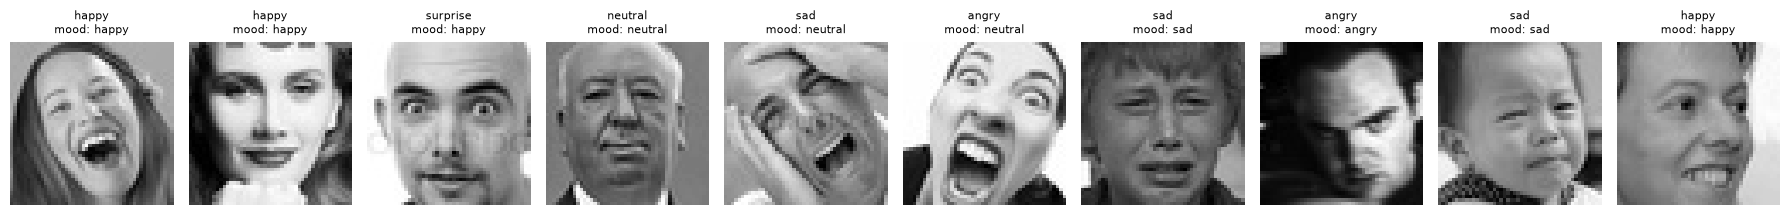

In [19]:
fig, axes = plt.subplots(1, len(session), figsize=(18, 3))
for ax, name, l in zip(axes, session, log):
    ax.imshow(cv2.imread(f"faces/{name}.jpg", 0), cmap="gray")
    ax.set_title(f"{l['frame_emotion']}\nmood: {l['smoothed_mood']}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Live webcam mode

Set `RUN_WEBCAM = True` to run the assistant on the laptop camera (press `q` to quit). It needs `opencv-python` (not the headless version) and does not run in Colab.

In [20]:
RUN_WEBCAM = False

if RUN_WEBCAM:
    cap = cv2.VideoCapture(0)
    bot = EmotionAssistant(window=10)
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        reply, info = bot.step(frame)
        for (x, y, w, h), emo, conf, _ in detect_emotions(frame):
            cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.putText(frame, f"{emo} {conf:.2f}", (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.putText(frame, reply[:60], (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        cv2.imshow("Emotion aware assistant", frame)
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    cap.release()
    cv2.destroyAllWindows()

**Conclusion**

Both assistants use a vision model only for perception. The useful part comes from what is done after: the label reader corrects OCR errors with a knowledge base and explains the medicine, and the emotion assistant smooths predictions over time and changes its behaviour based on the user's mood instead of reacting to a single frame.